# Pre-Project Data Observations for Housing Prices and Its Possible Covariates

In [2]:
# Import all the usual packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.optimize import curve_fit
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from IPython.display import display, HTML
from bs4 import BeautifulSoup
from pathlib import Path
from IPython.display import display, HTML, display, Image as IPythonImage


plt.rcParams.update({"figure.figsize": (8, 3), "font.size": 11})

In [6]:
data = pd.read_csv(r"C:\Users\mbadi\Downloads\MSPUS.csv")

# Turn data into a time series
data["observation_date"] = pd.to_datetime(data["observation_date"])
data.set_index("observation_date", inplace=True)

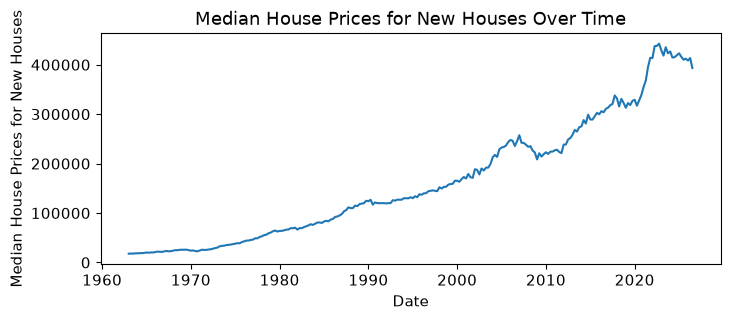

In [7]:
# Using plt, plot the data
plt.plot(data.index, data['MSPUS'])
plt.xlabel('Date')
plt.ylabel('Median House Prices for New Houses')
plt.title('Median House Prices for New Houses Over Time')
plt.show()

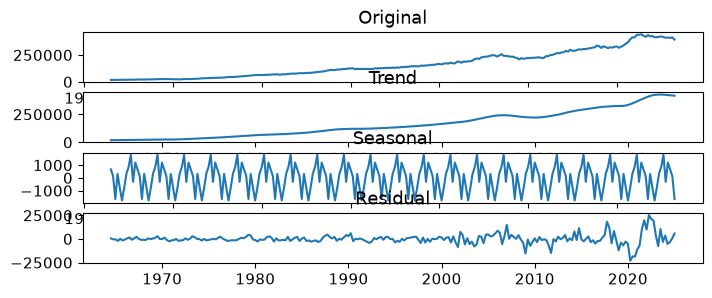

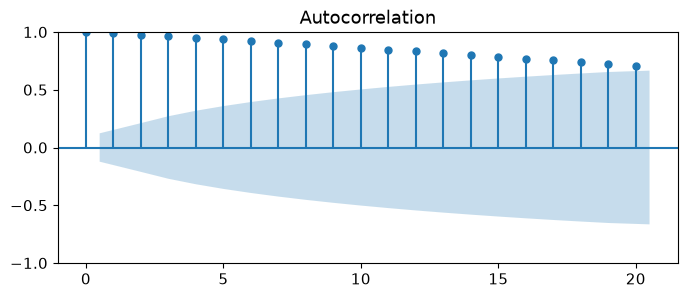

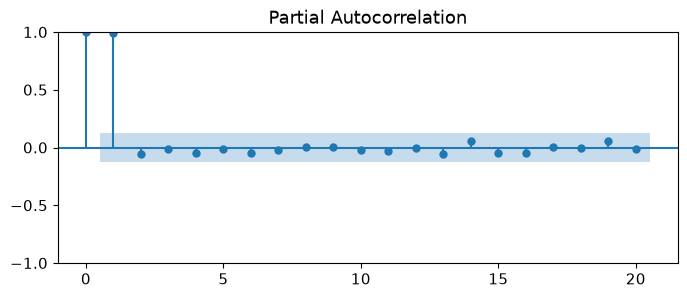

ADF Statistic: 1.2392447962215918
p-value: 0.9962461221536171


In [9]:
# Check the data for seasonality and trend using seasonal decomposition
decomposition = sm.tsa.seasonal_decompose(data['MSPUS'], model='additive', period=12)

# Plot the decomposed components
plt.subplot(4, 1, 1)
plt.plot(decomposition.observed)
plt.title('Original')
plt.subplot(4, 1, 2)
plt.plot(decomposition.trend)
plt.title('Trend')
plt.subplot(4, 1, 3)
plt.plot(decomposition.seasonal)
plt.title('Seasonal')
plt.subplot(4, 1, 4)
plt.plot(decomposition.resid)
plt.title('Residual')
plt.show()

# Numerically check for seasonality and trend using autocorrelation and partial autocorrelation plots
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(data['MSPUS'], lags=20)
plt.title('Autocorrelation')
plt.show()

plot_pacf(data['MSPUS'], lags=20)
plt.title('Partial Autocorrelation')
plt.show()

# Check for stationarity using the Augmented Dickey-Fuller test
from statsmodels.tsa.stattools import adfuller
result = adfuller(data['MSPUS'])
print('ADF Statistic:', result[0])
print('p-value:', result[1])

### The graphs show a partial autocorrelation with LAG(2) and autocorrelation that indicates non-stationarity, meaning differencing is likely necessary. Also, there is a strong seasonal trend that we need to account for.

In [11]:
# Test for breaks in the trend using the Chow test for COVID-19 in 2020 and the housing crash between 2007 and 2009
from statsmodels.stats.diagnostic import breaks_cusumolsresid
from scipy.stats import f

# Test for a break in 2020 (COVID-19)
def chow_test(series, break_date):
    y = series.dropna()
    t = np.arange(len(y))
    break_date = pd.Timestamp(break_date)

    before = y.index < break_date
    after = y.index >= break_date

    X = sm.add_constant(t)
    X_before, X_after = X[before], X[after]
    y_before, y_after = y[before], y[after]

    rss_restricted = np.sum(sm.OLS(y, X).fit().resid ** 2)
    rss_unrestricted = (
        np.sum(sm.OLS(y_before, X_before).fit().resid ** 2)
        + np.sum(sm.OLS(y_after, X_after).fit().resid ** 2)
    )

    k = X.shape[1]
    n = len(y)
    f_stat = ((rss_restricted - rss_unrestricted) / k) / (
        rss_unrestricted / (n - 2 * k)
    )
    p_value = 1 - f.cdf(f_stat, k, n - 2 * k)

    return f_stat, p_value

covid_test = chow_test(data["MSPUS"], "2020-01-01")
housing_test = chow_test(data["MSPUS"], "2008-01-01")

print("Break test for COVID-19 in 2020:", covid_test)
print("Break test for housing crash in 2008:", housing_test)

Break test for COVID-19 in 2020: (np.float64(156.74869737313506), np.float64(0.0))
Break test for housing crash in 2008: (np.float64(282.89635041379427), np.float64(0.0))


### Both tests show a break in the trend for COVID and the 2008 financial crisis that I need to account for.